# RVM-MobileNetV2 - Human Segmentation Fine-tuning
Notebook สำหรับเทรนและประเมินผล **RVM-MobileNetV2** บน Supervisely Filtered Person Dataset
- **Architecture**: RVM-MobileNetV2 (LR-ASPP + Recurrent ConvGRU Decoder + Segmentation Head)
- **Pretrained Weights**: ImageNet pretrained backbone
- **Training Strategy**: Encoder fine-tune ด้วย LR ต่ำ (1e-4) + LR-ASPP/Decoder/Head เทรนใหม่ (1e-3)
- **Input Resolution**: 256x256
- **Recurrent State**: รองรับ temporal memory (r1, r2, r3, r4) สำหรับวิดีโอ/webcam

In [1]:
import os
import sys
import random
import copy
import time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

# นำเข้าสถาปัตยกรรมโมเดล RVM
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from rvm_backbones import build_rvm

c:\College\Human-filter-for-video\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_ROOT = PROJECT_ROOT / "data" / "supervisely"
IMAGE_DIR = DATA_ROOT / "images"
MASK_DIR = DATA_ROOT / "masks"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"
PRED_DIR = OUTPUT_DIR / "predictions"
RESULT_DIR = OUTPUT_DIR / "results"

for folder in [CHECKPOINT_DIR, FIGURE_DIR, PRED_DIR, RESULT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODEL_VARIANT = "mobilenetv2"
MODEL_NAME = "RVM-MobileNetV2"
MODEL_TAG = "mobilenetv2"

CHECKPOINT_PATH = CHECKPOINT_DIR / f"rvm_{MODEL_TAG}_supervisely_best.pth"
HISTORY_PATH = RESULT_DIR / f"training_history_{MODEL_TAG}.csv"

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 20
LR_BACKBONE = 1e-4
LR_HEAD = 1e-3
WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project     :", PROJECT_ROOT)
print("Model       :", MODEL_NAME)
print("Device      :", device)
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))

Project     : C:\College\Human-filter-for-video
Model       : RVM-MobileNetV2
Device      : cuda
GPU         : NVIDIA GeForce RTX 5060 Laptop GPU


In [3]:
print("IMAGE_DIR exists:", IMAGE_DIR.exists())
print("MASK_DIR exists :", MASK_DIR.exists())

IMAGE_DIR exists: True
MASK_DIR exists : True


In [4]:
image_files = sorted([f for f in IMAGE_DIR.iterdir() if f.is_file()])
mask_files = sorted([f for f in MASK_DIR.iterdir() if f.is_file()])

print("Images:", len(image_files))
print("Masks :", len(mask_files))

Images: 2667
Masks : 2667


In [5]:
image_map = {p.stem: p for p in image_files}
mask_map = {p.stem: p for p in mask_files}

sample_ids = sorted(set(image_map.keys()) & set(mask_map.keys()))

print("Matched       :", len(sample_ids))
print("Missing masks :", len(set(image_map) - set(mask_map)))
print("Missing images:", len(set(mask_map) - set(image_map)))

Matched       : 2667
Missing masks : 0
Missing images: 0


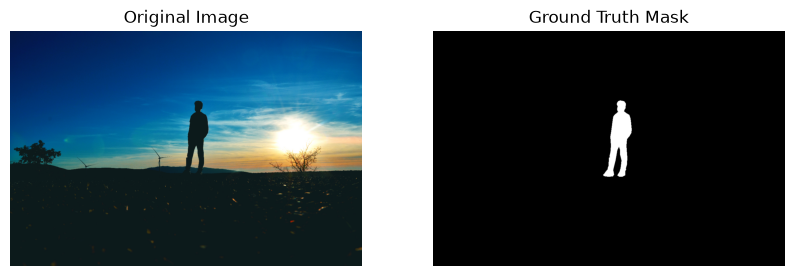

In [6]:
if sample_ids:
    sample_id = sample_ids[0]
    image = Image.open(image_map[sample_id]).convert("RGB")
    mask = Image.open(mask_map[sample_id]).convert("L")

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")
    plt.show()

In [7]:
generator = torch.Generator()
generator.manual_seed(SEED)

perm = torch.randperm(len(sample_ids), generator=generator).tolist()
n = len(sample_ids)
n_train = int(0.8 * n)
n_val = int(0.1 * n)

train_ids = [sample_ids[i] for i in perm[:n_train]]
val_ids = [sample_ids[i] for i in perm[n_train:n_train+n_val]]
test_ids = [sample_ids[i] for i in perm[n_train+n_val:]]

print("Total:", n)
print("Train:", len(train_ids))
print("Val  :", len(val_ids))
print("Test :", len(test_ids))

Total: 2667
Train: 2133
Val  : 266
Test : 268


In [8]:
class SuperviselyDataset(Dataset):
    def __init__(self, ids, image_map, mask_map, image_size=256, augment=False):
        self.ids = ids
        self.image_map = image_map
        self.mask_map = mask_map
        self.image_size = image_size
        self.augment = augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        sample_id = self.ids[index]
        image = Image.open(self.image_map[sample_id]).convert("RGB")
        mask = Image.open(self.mask_map[sample_id]).convert("L")

        image = TF.resize(
            image, [self.image_size, self.image_size],
            interpolation=InterpolationMode.BILINEAR, antialias=True
        )
        mask = TF.resize(
            mask, [self.image_size, self.image_size],
            interpolation=InterpolationMode.NEAREST
        )

        if self.augment and random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        # Apply appearance augmentation to training images only; masks stay unchanged.
        if self.augment and random.random() < 0.25:
            image = image.filter(ImageFilter.GaussianBlur(radius=random.uniform(0.3, 1.2)))

        image = TF.to_tensor(image)

        if self.augment and random.random() < 0.35:
            image = (image + torch.randn_like(image) * random.uniform(0.01, 0.05)).clamp_(0.0, 1.0)

        mask = (TF.pil_to_tensor(mask).float() > 127).float()
        return image, mask, sample_id

train_dataset = SuperviselyDataset(train_ids, image_map, mask_map, IMAGE_SIZE, augment=True)
val_dataset = SuperviselyDataset(val_ids, image_map, mask_map, IMAGE_SIZE, augment=False)
test_dataset = SuperviselyDataset(test_ids, image_map, mask_map, IMAGE_SIZE, augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

In [9]:
print(f"Building {MODEL_NAME}...")
model = build_rvm(MODEL_VARIANT, pretrained_backbone=True).to(device)
print(model)

Building RVM-MobileNetV2...
RVMSegmentation(
  (backbone): MobileNetV2Encoder(
    (stage1): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU6(inplace=True)
      )
      (1): InvertedResidual(
        (conv): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): ReLU6(inplace=True)
          )
          (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        )
      )
    )
    (stage2): Sequential(
      (2): InvertedResidual(
        

In [10]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")

Total parameters     : 2,417,917
Trainable parameters : 2,417,917


In [11]:
images, masks, ids = next(iter(val_loader))
images = images.to(device)
masks = masks.to(device)

model.eval()
with torch.no_grad():
    pred_seg, *rec = model(images, segmentation_pass=True)

print("Input shape       :", images.shape)
print("Prediction shape  :", pred_seg.shape)
print("Recurrent states  :", len(rec))

Input shape       : torch.Size([8, 3, 256, 256])
Prediction shape  : torch.Size([8, 1, 256, 256])
Recurrent states  : 4


In [12]:
criterion = nn.BCEWithLogitsLoss()

def calculate_metrics(logits, targets, threshold=0.5, eps=1e-8):
    probs = torch.sigmoid(logits)
    preds = probs >= threshold
    targets = targets >= 0.5

    tp = (preds & targets).sum().item()
    fp = (preds & ~targets).sum().item()
    fn = (~preds & targets).sum().item()

    iou = tp / (tp + fp + fn + eps)
    dice = 2 * tp / (2 * tp + fp + fn + eps)
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)

    return {
        "iou": iou,
        "dice": dice,
        "precision": precision,
        "recall": recall
    }

@torch.inference_mode()
def evaluate_model(model, loader):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    tp = fp = fn = 0

    for images, masks, _ in tqdm(loader, desc="Evaluating", leave=False):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        logits, *_ = model(images, segmentation_pass=True)
        loss = criterion(logits, masks)

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        preds = torch.sigmoid(logits) >= 0.5
        targets = masks >= 0.5

        tp += (preds & targets).sum().item()
        fp += (preds & ~targets).sum().item()
        fn += (~preds & targets).sum().item()

    eps = 1e-8
    return {
        "loss": total_loss / total_samples,
        "iou": tp / (tp + fp + fn + eps),
        "dice": 2 * tp / (2 * tp + fp + fn + eps),
        "precision": tp / (tp + fp + eps),
        "recall": tp / (tp + fn + eps)
    }

In [13]:
print(f"=== {MODEL_NAME} PRETRAINED BASELINE : VALIDATION ===")
baseline_val = evaluate_model(model, val_loader)
for k, v in baseline_val.items():
    print(f"{k:10s}: {v:.4f}")

print(f"\n=== {MODEL_NAME} PRETRAINED BASELINE : TEST ===")
baseline_test = evaluate_model(model, test_loader)
for k, v in baseline_test.items():
    print(f"{k:10s}: {v:.4f}")

baseline_df = pd.DataFrame([{
    "model": f"{MODEL_NAME} Pretrained Baseline",
    "loss": baseline_test["loss"],
    "iou": baseline_test["iou"],
    "dice": baseline_test["dice"],
    "precision": baseline_test["precision"],
    "recall": baseline_test["recall"]
}])
baseline_df.to_csv(RESULT_DIR / f"baseline_{MODEL_TAG}_results.csv", index=False)
baseline_df

=== RVM-MobileNetV2 PRETRAINED BASELINE : VALIDATION ===


loss      : 0.6840
iou       : 0.0000
dice      : 0.0000
precision : 1.0000
recall    : 0.0000

=== RVM-MobileNetV2 PRETRAINED BASELINE : TEST ===


loss      : 0.6853
iou       : 0.0000
dice      : 0.0000
precision : 1.0000
recall    : 0.0000


,model,loss,iou,dice,precision,recall
0,RVM-MobileNetV2 Pretrained Baseline,0.685272,1.713858e-07,3.427715e-07,1.0,1.713858e-07


In [14]:
# กำหนด Learning Rate แยก: Backbone (1e-4) สำหรับ Fine-tune, Decoder & Head (1e-3) สำหรับเทรนใหม่
param_groups = model.param_groups(lr_backbone=LR_BACKBONE, lr_head=LR_HEAD)
optimizer = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler(device.type, enabled=torch.cuda.is_available())

print("Optimizer:", optimizer)

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.0001
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 0.001
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [15]:
def train_one_epoch(model, loader, optimizer, scaler):
    model.train()
    running_loss = 0.0
    total_samples = 0

    for images, masks, _ in tqdm(loader, desc="Training", leave=False):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=torch.cuda.is_available()):
            logits, *_ = model(images, segmentation_pass=True)
            loss = criterion(logits.float(), masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        total_samples += images.size(0)

    return running_loss / total_samples

In [16]:
history = {
    "train_loss": [], "val_loss": [], "val_iou": [], "val_dice": [], "val_precision": [], "val_recall": []
}

best_val_loss = float("inf")
start_time = time.perf_counter()

print(f"Starting training {MODEL_NAME} for {EPOCHS} epochs...")

for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, optimizer, scaler)
    val_metrics = evaluate_model(model, val_loader)
    scheduler.step()

    history["train_loss"].append(train_loss)
    for k in ["loss", "iou", "dice", "precision", "recall"]:
        history[f"val_{k}"].append(val_metrics[k])

    print(
        f"Epoch {epoch + 1:2d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_metrics['loss']:.4f} | "
        f"Val IoU: {val_metrics['iou']:.4f} | Val Dice: {val_metrics['dice']:.4f}"
    )

    if val_metrics["loss"] < best_val_loss:
        best_val_loss = val_metrics["loss"]
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_metrics": val_metrics,
            "config": {
                "variant": MODEL_VARIANT,
                "image_size": IMAGE_SIZE,
                "batch_size": BATCH_SIZE,
                "epochs": EPOCHS,
                "lr_backbone": LR_BACKBONE,
                "lr_head": LR_HEAD,
                "seed": SEED
            }
        }, CHECKPOINT_PATH)
        print("  ✓ Best checkpoint saved")

training_seconds = time.perf_counter() - start_time
print(f"\nTraining complete in {training_seconds / 60:.2f} minutes.")
print(f"Best Validation Loss: {best_val_loss:.4f}")

Starting training RVM-MobileNetV2 for 20 epochs...


Epoch  1/20 | Train Loss: 0.2522 | Val Loss: 0.1257 | Val IoU: 0.8866 | Val Dice: 0.9399
  ✓ Best checkpoint saved


Epoch  2/20 | Train Loss: 0.1244 | Val Loss: 0.0956 | Val IoU: 0.8952 | Val Dice: 0.9447
  ✓ Best checkpoint saved


Epoch  3/20 | Train Loss: 0.0908 | Val Loss: 0.0787 | Val IoU: 0.9120 | Val Dice: 0.9540
  ✓ Best checkpoint saved


Epoch  4/20 | Train Loss: 0.0734 | Val Loss: 0.0746 | Val IoU: 0.9183 | Val Dice: 0.9574
  ✓ Best checkpoint saved


...

Epoch 16/20 | Train Loss: 0.0270 | Val Loss: 0.0603 | Val IoU: 0.9366 | Val Dice: 0.9672


Epoch 17/20 | Train Loss: 0.0266 | Val Loss: 0.0601 | Val IoU: 0.9385 | Val Dice: 0.9683


Epoch 18/20 | Train Loss: 0.0259 | Val Loss: 0.0578 | Val IoU: 0.9402 | Val Dice: 0.9692


Epoch 19/20 | Train Loss: 0.0259 | Val Loss: 0.0613 | Val IoU: 0.9389 | Val Dice: 0.9685


Epoch 20/20 | Train Loss: 0.0256 | Val Loss: 0.0577 | Val IoU: 0.9407 | Val Dice: 0.9694

Training complete in 33.97 minutes.
Best Validation Loss: 0.0574


Training history saved: C:\College\Human-filter-for-video\outputs\results\training_history_mobilenetv2.csv


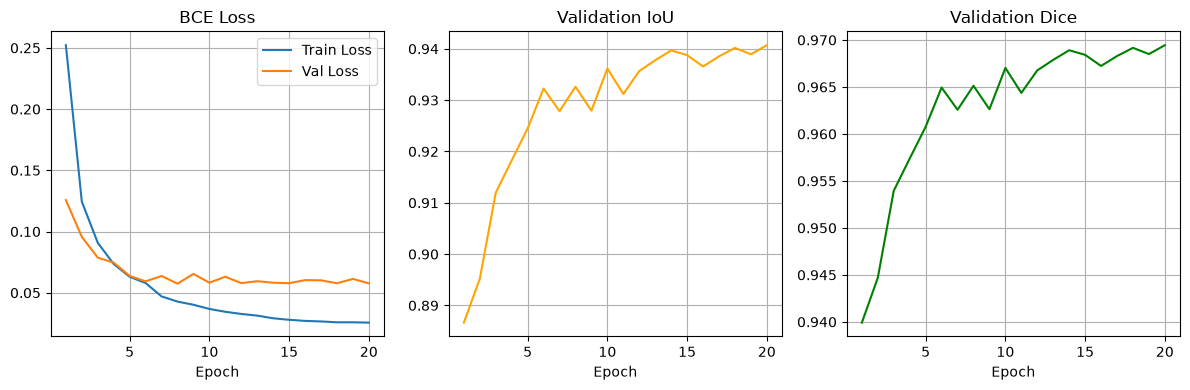

In [17]:
history_df = pd.DataFrame(history)
history_df.insert(0, "epoch", range(1, len(history_df) + 1))
history_df.to_csv(HISTORY_PATH, index=False)
print("Training history saved:", HISTORY_PATH)

epochs_range = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(epochs_range, history["train_loss"], label="Train Loss")
plt.plot(epochs_range, history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.title("BCE Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(epochs_range, history["val_iou"], color="orange")
plt.xlabel("Epoch")
plt.title("Validation IoU")
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(epochs_range, history["val_dice"], color="green")
plt.xlabel("Epoch")
plt.title("Validation Dice")
plt.grid(True)

plt.tight_layout()
plt.savefig(FIGURE_DIR / f"curves_{MODEL_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
print("Loading best checkpoint:")
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best epoch:", checkpoint["epoch"])
print("Best validation metrics:", checkpoint["val_metrics"])

fine_tuned_test = evaluate_model(model, test_loader)
print(f"\n=== {MODEL_NAME} FINE-TUNED : TEST ===")
for k, v in fine_tuned_test.items():
    print(f"{k:10s}: {v:.4f}")

Loading best checkpoint:
Best epoch: 8
Best validation metrics: {'loss': 0.057401853984683976, 'iou': 0.93260737101664, 'dice': 0.9651286495156498, 'precision': 0.9652235983878511, 'recall': 0.9650337193218163}



=== RVM-MobileNetV2 FINE-TUNED : TEST ===
loss      : 0.0684
iou       : 0.9269
dice      : 0.9620
precision : 0.9643
recall    : 0.9598


In [19]:
comparison = pd.DataFrame({
    "Metric": ["BCE Loss", "IoU", "Dice", "Precision", "Recall"],
    "Pretrained": [
        baseline_test["loss"], baseline_test["iou"], baseline_test["dice"],
        baseline_test["precision"], baseline_test["recall"]
    ],
    "Fine-tuned": [
        fine_tuned_test["loss"], fine_tuned_test["iou"], fine_tuned_test["dice"],
        fine_tuned_test["precision"], fine_tuned_test["recall"]
    ]
})
comparison["Change"] = comparison["Fine-tuned"] - comparison["Pretrained"]
comparison.to_csv(RESULT_DIR / f"baseline_vs_finetuned_{MODEL_TAG}.csv", index=False)
comparison

,Metric,Pretrained,Fine-tuned,Change
0,BCE Loss,6.852719e-01,0.068431,-0.616841
1,IoU,1.713858e-07,0.926865,0.926865
2,Dice,3.427715e-07,0.962045,0.962044
3,Precision,1.000000e+00,0.964325,-0.035675
4,Recall,1.713858e-07,0.959775,0.959775


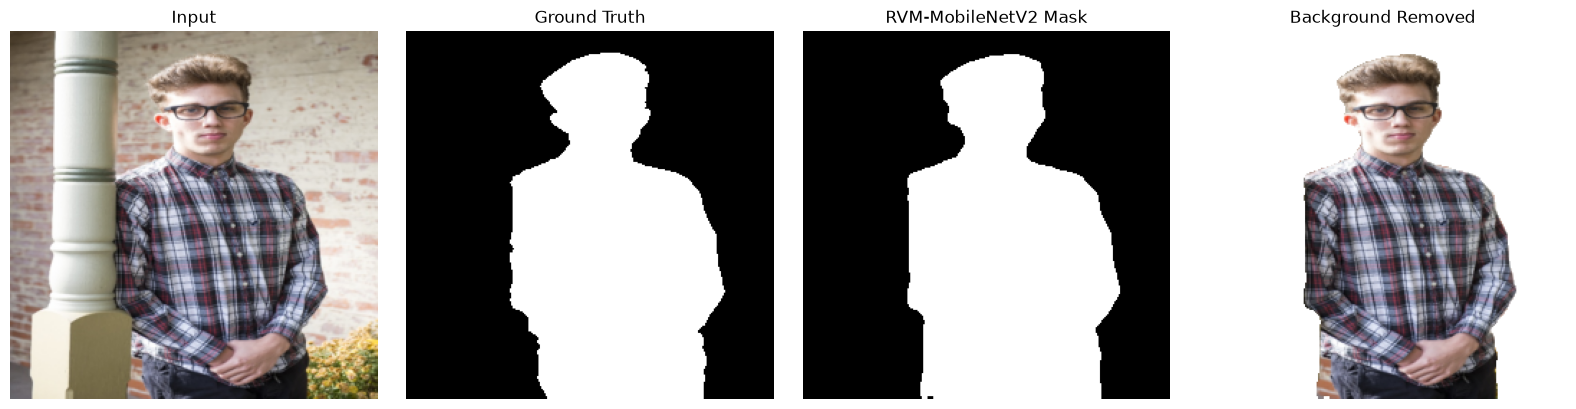

In [20]:
test_images, test_masks, test_ids_batch = next(iter(test_loader))
sample_image = test_images[0:1].to(device)
sample_mask = test_masks[0:1].to(device)

with torch.no_grad():
    tuned_logits, *_ = model(sample_image, segmentation_pass=True)
    tuned_prob = torch.sigmoid(tuned_logits)
    tuned_mask = (tuned_prob >= 0.5).float()

input_np = sample_image[0].permute(1, 2, 0).cpu().numpy()
gt_np = sample_mask[0, 0].cpu().numpy()
pred_np = tuned_mask[0, 0].cpu().numpy()

# Masked background removal
bg_removed = input_np * pred_np[..., None] + (1 - pred_np[..., None]) * 1.0

plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.imshow(input_np)
plt.title("Input")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(gt_np, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(pred_np, cmap="gray")
plt.title(f"{MODEL_NAME} Mask")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(bg_removed)
plt.title("Background Removed")
plt.axis("off")

plt.tight_layout()
plt.savefig(FIGURE_DIR / f"prediction_sample_{MODEL_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
summary = {
    "Model": MODEL_NAME,
    "Dataset": "Supervisely Filtered Person Dataset",
    "Total Samples": len(sample_ids),
    "Train Samples": len(train_ids),
    "Validation Samples": len(val_ids),
    "Test Samples": len(test_ids),
    "Input Resolution": f"{IMAGE_SIZE}x{IMAGE_SIZE}",
    "Batch Size": BATCH_SIZE,
    "Epochs": EPOCHS,
    "Optimizer": "AdamW",
    "LR Backbone": LR_BACKBONE,
    "LR Head": LR_HEAD,
    "Best Epoch": checkpoint["epoch"],
    "Training Time (sec)": training_seconds,
    "Baseline IoU": baseline_test["iou"],
    "Fine-tuned IoU": fine_tuned_test["iou"],
    "Baseline Dice": baseline_test["dice"],
    "Fine-tuned Dice": fine_tuned_test["dice"],
    "Baseline Precision": baseline_test["precision"],
    "Fine-tuned Precision": fine_tuned_test["precision"],
    "Baseline Recall": baseline_test["recall"],
    "Fine-tuned Recall": fine_tuned_test["recall"]
}

summary_df = pd.DataFrame([summary])
summary_df.T

,0
Model,RVM-MobileNetV2
Dataset,Supervisely Filtered Person Dataset
Total Samples,2667
Train Samples,2133
Validation Samples,266
Test Samples,268
Input Resolution,256x256
Batch Size,8
Epochs,20
Optimizer,AdamW


In [22]:
# Export TorchScript สำหรับนำไปรันบน Edge Computing / C++ / Web
model_cpu = copy.deepcopy(model).cpu().eval()
scripted_model = torch.jit.script(model_cpu)

EXPORT_PATH = CHECKPOINT_DIR / f"rvm_{MODEL_TAG}_finetuned.torchscript"
scripted_model.save(str(EXPORT_PATH))
print("Saved TorchScript model:", EXPORT_PATH)

Saved TorchScript model: C:\College\Human-filter-for-video\outputs\checkpoints\rvm_mobilenetv2_finetuned.torchscript
